In [2]:
import pandas as pd
import numpy as np
import os
from scipy import stats

In [3]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [4]:
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    log_loss,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,
    confusion_matrix,
    classification_report,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    roc_curve,
    auc
)

In [6]:
feature_cols = [
"CREDITCARD_AVG_LY_DRAWING_TO_PAYMENT_RATE",
"CREDITCARD_LAST_MONTH_INT_COVERAGE_RATIO",
"CREDITCARD_AVG_LY_ATMCOUNT_RATE",
"CREDITCARD_AVG_DRAWING_TO_PAYMENT_RATE",
"CREDITCARD_AVG_BALANCE_AMOUNT",
"CREDITCARD_LAST_MONTH_AMT_BALANCE",
"CREDITCARD_AVG_ATMCOUNT_RATE",
"CREDITCARD_AVG_LS_DRAWING_TO_PAYMENT_RATE",
"CREDITCARD_AVG_LS_ATMCOUNT_RATE",
"CREDITCARD_AVG_LY_PAYMENT_AMOUNT",
"CREDITCARD_LAST_MONTH_AMT_PAYMENT_TOTAL_CURRENT",
"CREDITCARD_AVG_INTCOVERAGE_RATE",
"CREDITCARD_AVG_POSCOUNT_RATE",
"CREDITCARD_AVG_LY_POSCOUNT_RATE",
"CREDITCARD_AVG_PAYMENT_AMOUNT",
"CREDITCARD_LAST_MONTH_CNT_DRAWINGS_CURRENT",
"CREDITCARD_LAST_MONTH_AMT_DRAWINGS_CURRENT",
"CREDITCARD_MAX_DURATION",
"CREDITCARD_LAST_MONTH_UTILIZATION_RATIO",
"CREDITCARD_AVG_LY_INTCOVERAGE_RATE",
"CREDITCARD_AVG_LS_INTCOVERAGE_RATE",
"CREDITCARD_AVG_LY_BALANCE_AMOUNT",
"CREDITCARD_AVG_DRAWING_AMOUNT",
"CREDITCARD_AVG_LY_ATMAMT_RATE",
"CREDITCARD_AVG_ATMAMT_RATE",
"CREDITCARD_AVG_LS_BALANCE_AMOUNT",
"CREDITCARD_AVG_LY_DRAWING_AMOUNT",
"CREDITCARD_LAST_MONTH_AMT_TOTAL_RECEIVABLE",
"CREDITCARD_LAST_MONTH_AMT_RECIVABLE",
"CREDITCARD_LAST_MONTH_AMT_RECEIVABLE_PRINCIPAL",
"CREDITCARD_AVG_LS_DRAWING_AMOUNT",
"CREDITCARD_AVG_LS_ATMAMT_RATE",
"CREDITCARD_AVG_LS_PAYMENT_AMOUNT",
"CREDITCARD_AVG_POSAMT_RATE",
"CREDITCARD_AVG_LY_POSAMT_RATE",
"CREDITCARD_AVG_LS_POSCOUNT_RATE",
"CREDITCARD_AVG_LS_POSAMT_RATE",
"CREDITCARD_LAST_MONTH_DRAWING_TO_PYMNT_RATIO",
"CREDITCARD_LAST_MONTH_PAYMENT_RATIO",
"CREDITCARD_AVG_LS_REPAYMENTCOUNT_RATE",
"CREDITCARD_LAST_MONTH_CNT_DRAWINGS_ATM_CURRENT",
"CREDITCARD_LAST_MONTH_ATM_DRAWING_AMT_RATIO",
"CREDITCARD_LAST_MONTH_POS_DRAWING_AMT_RATIO",
"CREDITCARD_AVG_LY_AMT_BALANCE_YOY_PCT_CHANGE",
"CREDITCARD_AVG_LY_REPAYMENTCOUNT_RATE",
"CREDITCARD_AVG_LS_AMT_BALANCE_YOY_PCT_CHANGE",
"CREDITCARD_LAST_MONTH_AMT_BALANCE_YOY_PCT_CHANGE",
"CREDITCARD_MAX_LY_DPDUTP",
"CREDITCARD_LY_DAYS_IN_DPD_RATIO",
"CREDITCARD_MAX_LS_DPDUTP",
"CREDITCARD_AVG_LY_AMT_DRAWINGS_CURRENT_YOY_PCT_CHANGE",
"CREDITCARD_LS_DAYS_IN_DPD_RATIO",
"CREDITCARD_AVG_AMT_BALANCE_YOY_PCT_CHANGE",
"CREDITCARD_MAX_LS_DPD",
"CREDITCARD_LAST_MONTH_AMT_DRAWINGS_CURRENT_YOY_PCT_CHANGE",
"CREDITCARD_LAST_MONTH_DPD_GE_1",
"CREDITCARD_MAX_UTILIZATION_RATE",
"CREDITCARD_MAX_LY_UTILIZATION_RATE",
"CREDITCARD_MAX_LS_UTILIZATION_RATE",
"CREDITCARD_AVG_LS_PAYMENT_RATE",
"CREDITCARD_AVG_LY_PAYMENT_RATE",
"CREDITCARD_LAST_MONTH_AMT_PAYMENT_CURRENT",
"CREDITCARD_LAST_MONTH_ATM_DRAWING_CNT_RATIO",
"CREDITCARD_LAST_MONTH_AMT_DRAWINGS_ATM_CURRENT",
"CREDITCARD_LAST_MONTH_CNT_DRAWINGS_POS_CURRENT",
"CREDITCARD_LAST_MONTH_POS_DRAWING_CNT_RATIO",
"CREDITCARD_AVG_PAYMENT_RATE",
"CREDITCARD_AVG_AMT_CREDIT_LIMIT_ACTUAL_YOY_PCT_CHANGE",
"CREDITCARD_LAST_MONTH_CNT_INSTALMENT_MATURE_CUM_YOY_ABS_CHANGE",
"CREDITCARD_AVG_LY_AMT_CREDIT_LIMIT_ACTUAL_YOY_PCT_CHANGE",
"CREDITCARD_AVG_LS_CNT_INSTALMENT_MATURE_CUM_YOY_ABS_CHANGE",
"CREDITCARD_AVG_LS_AMT_PAYMENT_TOTAL_CURRENT_YOY_PCT_CHANGE",
"CREDITCARD_LAST_MONTH_MONTHS_BALANCE",
"CREDITCARD_AVG_LY_CNT_INSTALMENT_MATURE_CUM_YOY_ABS_CHANGE",
"CREDITCARD_LAST_MONTH_CNT_INSTALMENT_MATURE_CUM",
"CREDITCARD_AVG_REPAYMENTCOUNT_RATE",
"CREDITCARD_AVG_CNT_INSTALMENT_MATURE_CUM_YOY_ABS_CHANGE",
"CREDITCARD_DAYS_TO_DPD_GE7",
"CREDITCARD_MAX_LY_DPD",
"CREDITCARD_MAX_DPD",
"CREDITCARD_AVG_LS_AMT_DRAWINGS_CURRENT_YOY_PCT_CHANGE",
"CREDITCARD_LAST_MONTH_AMT_PAYMENT_TOTAL_CURRENT_YOY_PCT_CHANGE",
"CREDITCARD_DAYS_TO_DPD_GE1",
"CREDITCARD_MAX_DPDUTP",
"CREDITCARD_DAYS_IN_DPD_RATIO",
"CREDITCARD_LAST_MONTH_DPD_UTP",
"CREDITCARD_LAST_MONTH_SK_DPD",
"CREDITCARD_AVG_LY_SK_DPD_YOY_ABS_CHANGE",
"CREDITCARD_AVG_LIMIT_AMOUNT",
"CREDITCARD_LAST_MONTH_SK_DPD_YOY_ABS_CHANGE"

]
target_col = 'TARGET'

In [7]:
os.getcwd()
os.chdir('a:\\Dominic\\My Projects\\Home Credit')

In [8]:
df = pd.read_parquet('src\\intermediate\\creditcard_processed.parquet')

In [9]:
X = df[feature_cols]
y = df[target_col]

In [10]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, log_loss
from hyperopt import fmin, tpe, hp, STATUS_OK, Trials

In [11]:
X.loc[X["CREDITCARD_LAST_MONTH_AMT_PAYMENT_CURRENT"].isna(),"CREDITCARD_LAST_MONTH_AMT_PAYMENT_CURRENT"] = -9999 

In [12]:
# --- 0. Prepare Sample Data ---
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=1994, stratify=y)

In [13]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
import xgboost as xgb

In [14]:
# --- 2. Define the Hyperparameter Search Space ---
space = {
    'n_estimators': hp.quniform('n_estimators', 50, 400, 10),
    'num_leaves': hp.quniform('num_leaves', 20, 60, 1),
    'max_depth': hp.quniform('max_depth', 3, 25, 1),
#    'learning_rate': hp.loguniform('learning_rate', np.log(0.01), np.log(0.2)),
#    'subsample': hp.uniform('subsample', 0.6, 1.0),
    'colsample_bytree': hp.uniform('colsample_bytree', 0.6, 1.0),
    'reg_alpha': hp.uniform('reg_alpha', 0.0, 1.0),
    'reg_lambda': hp.uniform('reg_lambda', 0.0, 1.0),
}

In [15]:
# --- 1. Define the Objective Function ---
def objective(params):
    """
    The objective function for Hyperopt to minimize.
    It trains a LightGBM model and returns the validation loss.
    """
    # Hyperopt sends integer parameters as floats, so we need to convert them
    params['num_leaves'] = int(params['num_leaves'])
    params['max_depth'] = int(params['max_depth'])
    params['n_estimators'] = int(params['n_estimators'])
    
    # Initialize and train the LightGBM model
    model = lgb.LGBMClassifier(
        objective='binary',
    #   metric='logloss',
        seed=42,
        n_jobs=4,
        verbose=-1,
        learning_rate = 0.015,
        subsample = 0.75,
        **params  # Unpack the dictionary of hyperparameters
    )
    
    # Use stratified K-fold for imbalanced datasets
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    
    # Get cross-validation scores
    scores = cross_val_score(model, X_train, y_train,
                            scoring='roc_auc', cv=cv, n_jobs=4)
    mean_score = scores.mean()
    # to minimize, we negate the score
    return -mean_score

In [16]:
# --- 3. Run the Optimization ---
# The Trials object will store the history of the search
trials = Trials()

# fmin is the optimization function
best_params = fmin(
    fn=objective,          # The function to minimize
    space=space,           # The hyperparameter space
    algo=tpe.suggest,      # The search algorithm (Tree-of-Parzen-Estimators)
    max_evals=150,         # The number of trials to run
    trials=trials          # The object to store the results
)

print("\n--- Hyperopt Search Complete ---")
print("Best hyperparameters found:")
# Convert float values back to int for integer parameters
best_params['n_estimators'] = int(best_params['n_estimators'])
best_params['num_leaves'] = int(best_params['num_leaves'])
best_params['max_depth'] = int(best_params['max_depth'])
print(best_params)

100%|██████████| 150/150 [12:00<00:00,  4.80s/trial, best loss: -0.6706844949638242]

--- Hyperopt Search Complete ---
Best hyperparameters found:
{'colsample_bytree': np.float64(0.949568913467135), 'max_depth': 13, 'n_estimators': 310, 'num_leaves': 23, 'reg_alpha': np.float64(0.8577028930912118), 'reg_lambda': np.float64(0.985627841884448)}


In [17]:
from lightgbm.callback import early_stopping, log_evaluation
from sklearn.metrics import f1_score

In [18]:
# Define the custom evaluation function for F1-score
def lgb_f1_score(y_true, y_pred):
    """
    Custom F1 score metric for LightGBM.
    """
    # y_pred will be probabilities, so we need to convert them to 0/1 predictions
    # using a standard 0.5 threshold.
    precision, recall, thresholds = precision_recall_curve(y_true, y_pred)

    # Calculate F1-score for each threshold
    # Note: We add a small epsilon to avoid division by zero
    f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)

    # Find the threshold that maximizes the F1-score
    best_f1_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_f1_idx]
    best_f1_score = f1_scores[best_f1_idx]

    y_pred_binary = (y_pred > best_threshold).astype(int)
    
    # Calculate F1 score
    score = f1_score(y_true, y_pred_binary)
    
    # The return format is (metric_name, metric_value, is_higher_better)
    return 'f1', score, True

In [19]:
# Initialize a new model with the best parameters
final_model = lgb.LGBMClassifier(
    objective='binary',
    seed=1994,
    **best_params               # Unpack the best parameters
)

final_model.fit(
    X_train, y_train,          # Training data
    eval_set=[(X_val, y_val)], # Validation data to monitor
    eval_metric='auc',         # Metric to track
    callbacks=[
        # Stop training if the 'auc' on the validation set
        # doesn't improve for 50 consecutive rounds.
        early_stopping(stopping_rounds=50),

        # Print the evaluation metric every 20 rounds.
        log_evaluation(period=20)
    ]
)

# Evaluate on test set
y_pred_proba = final_model.predict_proba(X_val)[:, 1]
test_auc = roc_auc_score(y_val, y_pred_proba)
print(f"Test AUC: {test_auc:.4f}")

[LightGBM] [Info] Number of positive: 6072, number of negative: 63889
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.018911 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 17621
[LightGBM] [Info] Number of data points in the train set: 69961, number of used features: 90
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.086791 -> initscore=-2.353459
[LightGBM] [Info] Start training from score -2.353459
Training until validation scores don't improve for 50 rounds
[20]	valid_0's auc: 0.657795	valid_0's binary_logloss: 0.281402
[40]	valid_0's auc: 0.660344	valid_0's binary_logloss: 0.281257
[60]	valid_0's auc: 0.660663	valid_0's binary_logloss: 0.281327
[80]	valid_0's auc: 0.65894	valid_0's binary_logloss: 0.281638
Early stopping, best iteration is:
[37]	valid_0's auc: 0.660764	valid_0's binary_logloss: 0.281137
Test AUC: 0.6608


In [20]:
# --- 4. Find the Optimal Threshold from the Precision-Recall Curve ---
# Get precision, recall, and thresholds
precision, recall, thresholds = precision_recall_curve(y_val, y_pred_proba)

# Calculate F1-score for each threshold
# Note: We add a small epsilon to avoid division by zero
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)

# Find the threshold that maximizes the F1-score
best_f1_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_f1_idx]
best_f1_score = f1_scores[best_f1_idx]

print(f"\n--- Finding the Optimal Threshold ---")
print(f"Best Threshold found: {best_threshold:.4f}")
print(f"F1-Score at this threshold: {best_f1_score:.4f}\n")

# Evaluate performance at the new, optimal threshold
y_pred_optimal = (y_pred_proba >= best_threshold) * 1

print(f"--- Performance at Optimal Threshold ({best_threshold:.2f}) ---")
print(classification_report(y_val, y_pred_optimal))


--- Finding the Optimal Threshold ---
Best Threshold found: 0.1163
F1-Score at this threshold: 0.2512

--- Performance at Optimal Threshold (0.12) ---
              precision    recall  f1-score   support

           0       0.94      0.84      0.88     15973
           1       0.19      0.39      0.25      1518

    accuracy                           0.80     17491
   macro avg       0.56      0.61      0.57     17491
weighted avg       0.87      0.80      0.83     17491



In [21]:
# Create a DataFrame to view feature importances clearly
importances = pd.DataFrame({
    'feature': final_model.feature_name_,
    'importance': final_model.feature_importances_
}).sort_values('importance', ascending=False).reset_index(drop=True)

print("Feature importances:")
print(importances)

Feature importances:
                                              feature  importance
0                         CREDITCARD_AVG_LIMIT_AMOUNT          62
1             CREDITCARD_LAST_MONTH_UTILIZATION_RATIO          34
2                             CREDITCARD_MAX_DURATION          32
3                     CREDITCARD_MAX_UTILIZATION_RATE          28
4           CREDITCARD_AVG_AMT_BALANCE_YOY_PCT_CHANGE          24
..                                                ...         ...
85  CREDITCARD_AVG_LS_CNT_INSTALMENT_MATURE_CUM_YO...           0
86                                 CREDITCARD_MAX_DPD           0
87                              CREDITCARD_MAX_DPDUTP           0
88                      CREDITCARD_LAST_MONTH_DPD_UTP           0
89                       CREDITCARD_LAST_MONTH_SK_DPD           0

[90 rows x 2 columns]


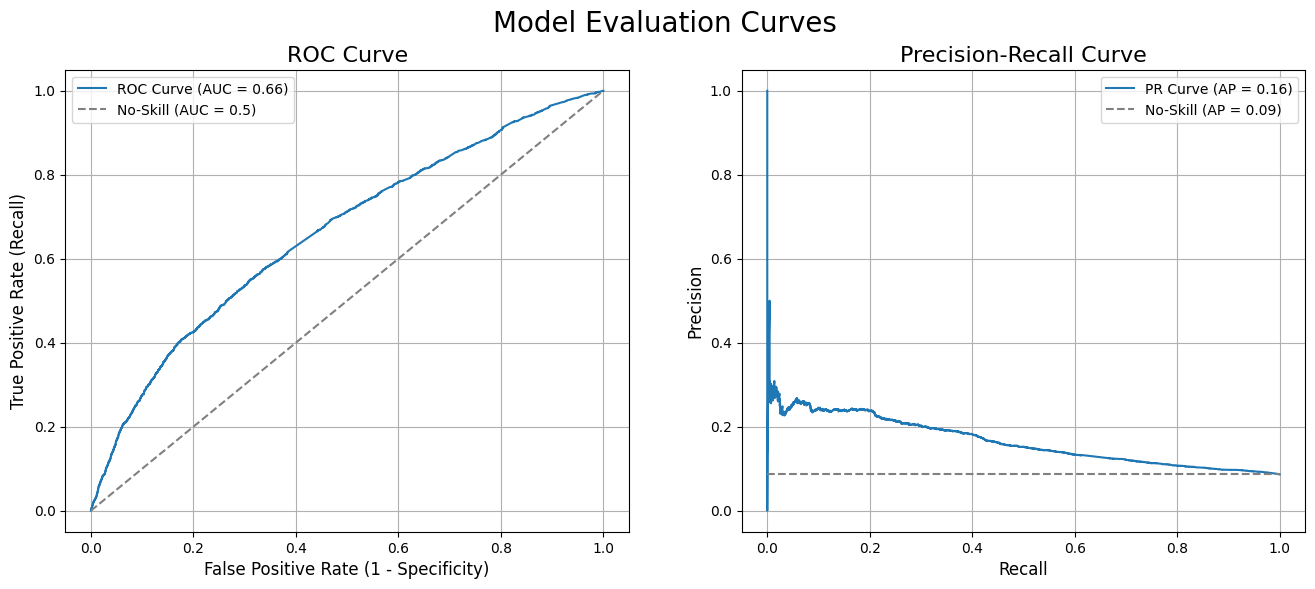

In [ ]:
# For ROC Curve
y_pred_proba = y_pred_optimal
fpr, tpr, roc_thresholds = roc_curve(y_val, y_pred_proba)
roc_auc = roc_auc_score(y_val, y_pred_proba)

# For Precision-Recall Curve
precision, recall, pr_thresholds = precision_recall_curve(y_val, y_pred_proba)
pr_auc = auc(recall, precision)

# Create a figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- Plot 1: ROC Curve ---
ax1.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})')
ax1.plot([0, 1], [0, 1], linestyle='--', color='gray', label='No-Skill (AUC = 0.5)')
ax1.set_title('ROC Curve', fontsize=16)
ax1.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
ax1.set_ylabel('True Positive Rate (Recall)', fontsize=12)
ax1.legend()
ax1.grid(True)

# --- Plot 2: Precision-Recall Curve ---
ax2.plot(recall, precision, label=f'PR Curve (AP = {pr_auc:.2f})')
no_skill = len(y_val[y_val==1]) / len(y_val)
ax2.plot([0, 1], [no_skill, no_skill], linestyle='--', color='gray', label=f'No-Skill (AP = {no_skill:.2f})')
ax2.set_title('Precision-Recall Curve', fontsize=16)
ax2.set_xlabel('Recall', fontsize=12)
ax2.set_ylabel('Precision', fontsize=12)
ax2.legend()
ax2.grid(True)

# Add a main title and show the plot
fig.suptitle('Model Evaluation Curves', fontsize=20)
plt.show()

In [23]:
# 4. Calculate and print metrics
print(f"Accuracy: {accuracy_score(y_val, y_pred_labels):.4f} (Can be misleading on imbalanced data)\n")

# Metrics that require probabilities
print(f"AUC Score: {roc_auc_score(y_val, y_pred_labels):.4f}")
print(f"Log Loss: {log_loss(y_val, y_pred_labels):.4f}\n")

# Metrics that require binary labels
print(f"Precision: {precision_score(y_val, y_pred_labels):.4f}")
print(f"Recall (Sensitivity): {recall_score(y_val, y_pred_labels):.4f}")
print(f"F1-Score: {f1_score(y_val, y_pred_labels):.4f}\n")

NameError: name 'y_pred_labels' is not defined

In [24]:
from sklearn.naive_bayes import GaussianNB

# 1. Initialize the model
nb = GaussianNB()

# 2. Train the model
print("Training Naive Bayes...")
nb.fit(X_train, y_train)

# 3. Make predictions and evaluate
y_pred_proba = nb.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred_proba)

print(f"\nNaive Bayes AUC Score: {auc:.4f}")

Training Naive Bayes...

Naive Bayes AUC Score: 0.6006


In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

In [26]:
# Handle missing values
# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#X_train, X_val, y_train, y_val = train_test_split(X_scaled, y, test_size=0.20, random_state=17,stratify=y)

# Fit logistic regression model
model = LogisticRegression(random_state=124, max_iter=10000, penalty='l1', solver='liblinear', C=0.1)
model.fit(X_train, y_train)

# Create DataFrame with coefficients
coef_df = pd.DataFrame({'variable': feature_cols, 'coef': model.coef_[0]})

In [27]:
y_pred_proba = model.predict_proba(X_val)[:, 1]  # This will give the predicted probabilities for the validation set

In [28]:
# --- 4. Find the Optimal Threshold from the Precision-Recall Curve ---
# Get precision, recall, and thresholds
precision, recall, thresholds = precision_recall_curve(y_val, y_pred_proba)

# Calculate F1-score for each threshold
# Note: We add a small epsilon to avoid division by zero
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)

# Find the threshold that maximizes the F1-score
best_f1_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_f1_idx]
best_f1_score = f1_scores[best_f1_idx]

print(f"\n--- Finding the Optimal Threshold ---")
print(f"Best Threshold found: {best_threshold:.4f}")
print(f"F1-Score at this threshold: {best_f1_score:.4f}\n")

# Evaluate performance at the new, optimal threshold
y_pred_optimal = (y_pred_proba >= best_threshold) * 1

print(f"--- Performance at Optimal Threshold ({best_threshold:.2f}) ---")
print(classification_report(y_val, y_pred_optimal))


--- Finding the Optimal Threshold ---
Best Threshold found: 0.1196
F1-Score at this threshold: 0.2435

--- Performance at Optimal Threshold (0.12) ---
              precision    recall  f1-score   support

           0       0.93      0.82      0.88     15973
           1       0.18      0.40      0.24      1518

    accuracy                           0.79     17491
   macro avg       0.56      0.61      0.56     17491
weighted avg       0.87      0.79      0.82     17491



In [29]:
roc_auc = roc_auc_score(y_val, y_pred_proba)
print(f"ROC AUC Score: {roc_auc:.4f}")

ROC AUC Score: 0.6483


In [30]:
# --- 1. Define the Objective Function ---
def objective(params):
    """
    The objective function for Hyperopt to minimize.
    It trains a LightGBM model and returns the validation loss.
    """
    # Hyperopt sends integer parameters as floats, so we need to convert them
    params['num_leaves'] = int(params['num_leaves'])
    params['max_depth'] = int(params['max_depth'])
    params['n_estimators'] = int(params['n_estimators'])
    
    # Initialize the XGBoost model
    model = xgb.XGBClassifier(
        objective='binary:logistic',
        eval_metric='auc',
        random_state=42,
        use_label_encoder=False,
        n_jobs=-1,
        **params  # Unpack the dictionary of hyperparameters
    )

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    
    mean_auc = cross_val_score(model, X_train, y_train,
                               scoring='roc_auc', cv=cv, n_jobs=-1).mean()

    # Return the standard Hyperopt dictionary format
    return {'loss': -mean_auc, 'status': STATUS_OK}

In [ ]:
# --- 3. Run the Optimization ---
# The Trials object will store the history of the search
trials = Trials()

# fmin is the optimization function
best_params = fmin(
    fn=objective,          # The function to minimize
    space=space,           # The hyperparameter space
    algo=tpe.suggest,      # The search algorithm (Tree-of-Parzen-Estimators)
    max_evals=150,         # The number of trials to run
    trials=trials          # The object to store the results
)

print("\n--- Hyperopt Search Complete ---")
print("Best hyperparameters found:")
# Convert float values back to int for integer parameters
best_params['n_estimators'] = int(best_params['n_estimators'])
best_params['num_leaves'] = int(best_params['num_leaves'])
best_params['max_depth'] = int(best_params['max_depth'])
print(best_params)

  6%|▌         | 9/150 [04:41<1:20:22, 34.20s/trial, best loss: -0.659847674557121] 

In [99]:
# 1. Initialize the XGBoost model
# 'eval_metric' is set to avoid a future deprecation warning.
xgboost_model = xgb.XGBClassifier(
    random_state=42,
    eval_metric='auc',
    **best_params
)

# 2. Train the model
print("Training XGBoost...")
xgboost_model.fit(X_train, y_train)

# 3. Make predictions and evaluate
y_pred_proba = xgboost_model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred_proba)

print(f"\nXGBoost AUC Score: {auc:.4f}")

Training XGBoost...


a:\Dominic\My Projects\Home Credit\project_env\Lib\site-packages\xgboost\training.py:183: UserWarning: [10:30:51] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "num_leaves" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



XGBoost AUC Score: 0.6646


In [100]:
# --- 4. Find the Optimal Threshold from the Precision-Recall Curve ---
# Get precision, recall, and thresholds
precision, recall, thresholds = precision_recall_curve(y_val, y_pred_proba)

# Calculate F1-score for each threshold
# Note: We add a small epsilon to avoid division by zero
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)

# Find the threshold that maximizes the F1-score
best_f1_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_f1_idx]
best_f1_score = f1_scores[best_f1_idx]

print(f"\n--- Finding the Optimal Threshold ---")
print(f"Best Threshold found: {best_threshold:.4f}")
print(f"F1-Score at this threshold: {best_f1_score:.4f}\n")

# Evaluate performance at the new, optimal threshold
y_pred_optimal = (y_pred_proba >= best_threshold) * 1

print(f"--- Performance at Optimal Threshold ({best_threshold:.2f}) ---")
print(classification_report(y_val, y_pred_optimal))


--- Finding the Optimal Threshold ---
Best Threshold found: 0.1225
F1-Score at this threshold: 0.2444

--- Performance at Optimal Threshold (0.12) ---
              precision    recall  f1-score   support

           0       0.93      0.84      0.89     15973
           1       0.18      0.37      0.24      1518

    accuracy                           0.80     17491
   macro avg       0.56      0.61      0.57     17491
weighted avg       0.87      0.80      0.83     17491

